# **Mini proyecto número 2**
`Bioinfromática 2026`

*Docente: Esp. Lic Ignacio Labari*

*Alumna: López Solana Rocío*

### Introducción al dataset

Se trabajará con el dataset **Differentiated Thyroid Cancer Recurrence**, que contiene información clínica de **383 pacientes** con cáncer diferenciado de tiroides.

El conjunto de datos posee **17 columnas** en total: **16 características clínicas** y una variable objetivo llamada `Recurred`. Entre las características se incluyen la edad, género, tabaquismo, antecedentes de radioterapia, función tiroidea, examen físico, adenopatías, tipo de patología, focalidad del tumor, nivel de riesgo, clasificación TNM, estadio y respuesta al tratamiento.

La variable objetivo `Recurred` indica si el paciente presentó recurrencia del cáncer (`Yes`) o no (`No`).

El objetivo del análisis será estudiar estas características y aplicar técnicas de Machine Learning para predecir la recurrencia del cáncer de tiroides.

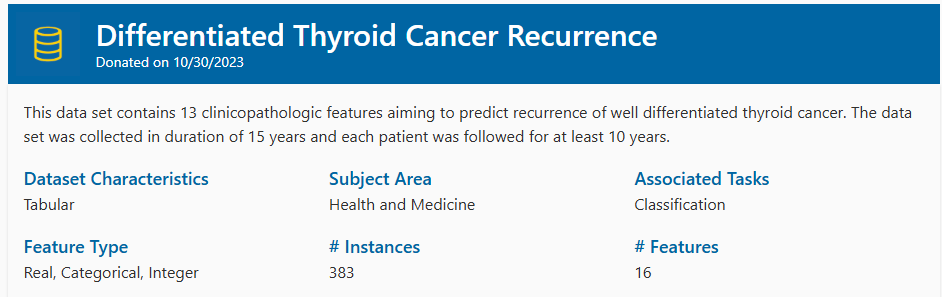

# **1) Descargar el dataset**

# **2) Abrir el dataset**

In [ ]:
# Importar la herramienta para subir archivos a Colab
from google.colab import files

# Seleccionar y subir el archivo desde la computadora
uploaded = files.upload()

Saving Thyroid_Diff.csv to Thyroid_Diff.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("Thyroid_Diff.csv") # Leer el dataset
df

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,72,M,Yes,Yes,Yes,Euthyroid,Single nodular goiter-right,Right,Papillary,Uni-Focal,High,T4b,N1b,M1,IVB,Biochemical Incomplete,Yes
379,81,M,Yes,No,Yes,Euthyroid,Multinodular goiter,Extensive,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
380,72,M,Yes,Yes,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
381,61,M,Yes,Yes,Yes,Clinical Hyperthyroidism,Multinodular goiter,Extensive,Hurthel cell,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes


**¿Cuántas columnas hay? Describir cada una de ellas.**


Hay 383 filas, que corresponden a 1 por paciente, y 17 columnas. De esas 17 columnas, 16 son features y 1 es la variable objetivo.

In [ ]:
# Mostrar el nombre de todas las columnas
df.columns

Index(['Age', 'Gender', 'Smoking', 'Hx Smoking', 'Hx Radiothreapy',
       'Thyroid Function', 'Physical Examination', 'Adenopathy', 'Pathology',
       'Focality', 'Risk', 'T', 'N', 'M', 'Stage', 'Response', 'Recurred'],
      dtype='object')

| Columna | Qué representa |
|---|---|
| `Age` | Edad del paciente |
| `Gender` | Género |
| `Smoking` | Si fuma o no |
| `Hx Smoking` | Antecedentes de tabaquismo |
| `Hx Radiothreapy` | Antecedentes de radioterapia |
| `Thyroid Function` | Estado de la función tiroidea |
| `Physical Examination` | Resultado del examen físico |
| `Adenopathy` | Presencia/localización de adenopatías |
| `Pathology` | Tipo histológico del cáncer |
| `Focality` | Si el tumor es unifocal o multifocal |
| `Risk` | Nivel de riesgo |
| `T` | Clasificación del tumor primario |
| `N` | Afectación de ganglios linfáticos |
| `M` | Presencia de metástasis a distancia |
| `Stage` | Estadio del cáncer |
| `Response` | Respuesta al tratamiento |
| `Recurred` | Si el cáncer recurrió o no |

**¿Cúal es la variable objetivo, y cuáles y cuántas son las clases que toma la misma?**

La variable objetivo es Recurred y posee 2 clases: No y Yes, que indican si el paciente presentó o no recurrencia del cáncer.

In [ ]:
# Mostrar los valores posibles de la variable objetivo
df['Recurred'].unique()

array(['No', 'Yes'], dtype=object)

In [ ]:
# Cantidad de clases de la variable objetivo
df['Recurred'].nunique()

2

In [ ]:
# Cantidad de pacientes pertenecientes a cada clase
df['Recurred'].value_counts()

,count
Recurred,
No,275
Yes,108


**¿Cuántos features numéricos y categóricos tiene?**

El dataset tiene 1 feature numérico (la edad) y 15 features categóricos.

In [ ]:
# Mostrar el tipo de dato de cada columna
df.dtypes

,0
Age,int64
Gender,object
Smoking,object
Hx Smoking,object
Hx Radiothreapy,object
Thyroid Function,object
Physical Examination,object
Adenopathy,object
Pathology,object
Focality,object


In [ ]:
# Separar las features de la variable objetivo
X = df.drop(columns=['Recurred'])

# Identificar features numéricas
features_numericas = X.select_dtypes(include=['number']).columns

# Identificar features categóricas
features_categoricas = X.select_dtypes(include=['object']).columns

# Mostrar cantidades
print("Features numéricas:", len(features_numericas))
print("Features categóricas:", len(features_categoricas))

Features numéricas: 1
Features categóricas: 15


**De las features numéricas, ¿cuáles son sus mínimos y máximos?**

La edad mínima es de 15 años y la máxima de 82 años.

In [ ]:
# Obtener información estadística de las features numéricas
df[features_numericas].describe()

,Age
count,383.000000
mean,40.866841
std,15.134494
min,15.000000
25%,29.000000
50%,37.000000
75%,51.000000
max,82.000000


In [ ]:
# Mostrar solamente mínimo y máximo
df[features_numericas].describe().loc[['min', 'max']]

,Age
min,15.0
max,82.0


**¿Cuántos valores únicos tienen las features categóricas?**

In [ ]:
# Recorrer las features categóricas
for columna in features_categoricas:
    print(columna)
    print("Cantidad de valores únicos:", df[columna].nunique())
    print("Valores:", df[columna].unique())
    print()

Gender
Cantidad de valores únicos: 2
Valores: ['F' 'M']

Smoking
Cantidad de valores únicos: 2
Valores: ['No' 'Yes']

Hx Smoking
Cantidad de valores únicos: 2
Valores: ['No' 'Yes']

Hx Radiothreapy
Cantidad de valores únicos: 2
Valores: ['No' 'Yes']

Thyroid Function
Cantidad de valores únicos: 5
Valores: ['Euthyroid' 'Clinical Hyperthyroidism' 'Clinical Hypothyroidism'
 'Subclinical Hyperthyroidism' 'Subclinical Hypothyroidism']

Physical Examination
Cantidad de valores únicos: 5
Valores: ['Single nodular goiter-left' 'Multinodular goiter'
 'Single nodular goiter-right' 'Normal' 'Diffuse goiter']

Adenopathy
Cantidad de valores únicos: 6
Valores: ['No' 'Right' 'Extensive' 'Left' 'Bilateral' 'Posterior']

Pathology
Cantidad de valores únicos: 4
Valores: ['Micropapillary' 'Papillary' 'Follicular' 'Hurthel cell']

Focality
Cantidad de valores únicos: 2
Valores: ['Uni-Focal' 'Multi-Focal']

Risk
Cantidad de valores únicos: 3
Valores: ['Low' 'Intermediate' 'High']

T
Cantidad de valores ún

# **3) Preparación de los datos**




**¿Hay valores faltantes? ¿Cuántos?
Si deciden eliminar las filas con valores faltantes, ¿cuantas eliminarían?**

In [ ]:
# Mostrar cuántos valores faltantes hay en cada columna
df.isnull().sum()

,0
Age,0
Gender,0
Smoking,0
Hx Smoking,0
Hx Radiothreapy,0
Thyroid Function,0
Physical Examination,0
Adenopathy,0
Pathology,0
Focality,0


Vamos que no hay valores faltantes, tal como lo indicaba el dataset.

Pasamos las variables categóricas a números usando `LabelEncoder` :

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Crear una copia del dataframe original
datos_limpios = df.copy()

# Separar las features y la variable objetivo
X = datos_limpios.iloc[:, :-1]
y = datos_limpios.iloc[:, -1]

# Buscar las columnas categóricas de X
columnas_categoricas = X.select_dtypes(include=['object']).columns

# Transformar las variables categóricas de X a números
for columna in columnas_categoricas:

    # Crear una instancia de LabelEncoder
    label_encoder = LabelEncoder()

    # Ajustar el codificador y transformar la columna
    X[columna] = label_encoder.fit_transform(X[columna])

    # Mostrar las correspondencias
    label_mapping = dict(
        zip(
            label_encoder.classes_,
            range(len(label_encoder.classes_))
        )
    )

    print(f"Correspondencia para {columna}:")
    print(label_mapping)
    print()

Correspondencia para Gender:
{'F': 0, 'M': 1}

Correspondencia para Smoking:
{'No': 0, 'Yes': 1}

Correspondencia para Hx Smoking:
{'No': 0, 'Yes': 1}

Correspondencia para Hx Radiothreapy:
{'No': 0, 'Yes': 1}

Correspondencia para Thyroid Function:
{'Clinical Hyperthyroidism': 0, 'Clinical Hypothyroidism': 1, 'Euthyroid': 2, 'Subclinical Hyperthyroidism': 3, 'Subclinical Hypothyroidism': 4}

Correspondencia para Physical Examination:
{'Diffuse goiter': 0, 'Multinodular goiter': 1, 'Normal': 2, 'Single nodular goiter-left': 3, 'Single nodular goiter-right': 4}

Correspondencia para Adenopathy:
{'Bilateral': 0, 'Extensive': 1, 'Left': 2, 'No': 3, 'Posterior': 4, 'Right': 5}

Correspondencia para Pathology:
{'Follicular': 0, 'Hurthel cell': 1, 'Micropapillary': 2, 'Papillary': 3}

Correspondencia para Focality:
{'Multi-Focal': 0, 'Uni-Focal': 1}

Correspondencia para Risk:
{'High': 0, 'Intermediate': 1, 'Low': 2}

Correspondencia para T:
{'T1a': 0, 'T1b': 1, 'T2': 2, 'T3a': 3, 'T3b': 4, 

Hacemos lo mismo pero para las clases (y):

In [ ]:
# Crear una instancia de LabelEncoder para las clases
label_encoder = LabelEncoder()

# Transformar las etiquetas en valores numéricos
y = label_encoder.fit_transform(y)

# Imprimir las correspondencias entre etiquetas originales y números
label_mapping = dict(
    zip(
        label_encoder.classes_,
        range(len(label_encoder.classes_))
    )
)

print("Correspondencia entre etiquetas originales y valores numéricos:")
print(label_mapping)

Correspondencia entre etiquetas originales y valores numéricos:
{'No': 0, 'Yes': 1}


Entonces:
- 0 → no hubo recurrencia.
- 1 → sí hubo recurrencia.

In [ ]:
# Asegurar que X sea un DataFrame
X_df = pd.DataFrame(X)

# Asegurar que y sea un DataFrame
y_df = pd.DataFrame(y, columns=['Recurred'])

# Imprimir las primeras filas para verificar
print("DataFrame 'X_df':")
print(X_df.head())

print("\nDataFrame 'y_df':")
print(y_df.head())

DataFrame 'X_df':
   Age  Gender  Smoking  Hx Smoking  Hx Radiothreapy  Thyroid Function  \
0   27       0        0           0                0                 2   
1   34       0        0           1                0                 2   
2   30       0        0           0                0                 2   
3   62       0        0           0                0                 2   
4   62       0        0           0                0                 2   

   Physical Examination  Adenopathy  Pathology  Focality  Risk  T  N  M  \
0                     3           3          2         1     2  0  0  0   
1                     1           3          2         1     2  0  0  0   
2                     4           3          2         1     2  0  0  0   
3                     4           3          2         1     2  0  0  0   
4                     1           3          2         0     2  0  0  0   

   Stage  Response  
0      0         2  
1      0         1  
2      0         1  
3 

In [ ]:
# Volver a unir las features codificadas y la variable objetivo

datos_limpios = X_df.copy()
datos_limpios['Recurred'] = y

# Verificar los tipos de datos
print(datos_limpios.dtypes)

Age                     int64
Gender                  int64
Smoking                 int64
Hx Smoking              int64
Hx Radiothreapy         int64
Thyroid Function        int64
Physical Examination    int64
Adenopathy              int64
Pathology               int64
Focality                int64
Risk                    int64
T                       int64
N                       int64
M                       int64
Stage                   int64
Response                int64
Recurred                int64
dtype: object


Guardamos el DataFrame limpio en un archivo de texto

In [ ]:
# Guardar el dataframe limpio en un archivo de texto
datos_limpios.to_csv('datos_limpios.txt', index=False)

**¿Las clases están balanceadas? ¿Cuántos datos tiene cada una de ellas?**



In [ ]:
# Contar cuántos datos pertenecen a cada clase
datos_limpios['Recurred'].value_counts()

,count
Recurred,
0,275
1,108


In [ ]:
# Mostrar el porcentaje correspondiente a cada clase
datos_limpios['Recurred'].value_counts(normalize=True) * 100

,proportion
Recurred,
0,71.801567
1,28.198433


Las clases no están balanceadas. Aproximadamente el 71,8 % de los pacientes no presentó recurrencia, mientras que el 28,2 % sí presentó recurrencia.

# **4) Visualización y reducción de la dimensionalidad de los datos**


**¿Cuántas dimensiones habría en el caso que uno quisiera utilizar directamente a todos los features para graficar?**



Como tenemos 16 features, si quisiéramos representar todas directamente necesitaríamos un espacio de 16 dimensiones. O sea que cada paciente estaría representado en un espacio de 16D, algo imposible ver.

**¿Las features están todas medidas con las mismas unidades?**


No. La feature "Age" originalmente está expresada en años, mientras que las demás variables son categorías que transformamos a números con LabelEncoder.

Separaramos los datos de las clases. Guardamos en ‘X’ las features y en ‘y’ las etiquetas (clases)

In [ ]:
# X contiene las 16 características de los pacientes
X = datos_limpios.drop(columns=['Recurred'])

# y contiene la variable objetivo
y = datos_limpios['Recurred']

# Mostrar X
X

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response
0,27,0,0,0,0,2,3,3,2,1,2,0,0,0,0,2
1,34,0,0,1,0,2,1,3,2,1,2,0,0,0,0,1
2,30,0,0,0,0,2,4,3,2,1,2,0,0,0,0,1
3,62,0,0,0,0,2,4,3,2,1,2,0,0,0,0,1
4,62,0,0,0,0,2,1,3,2,0,2,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,72,1,1,1,1,2,4,5,3,1,0,6,2,1,4,0
379,81,1,1,0,1,2,1,1,3,0,0,6,2,1,4,3
380,72,1,1,1,0,2,1,0,3,0,0,6,2,1,4,3
381,61,1,1,1,1,0,1,1,1,0,0,6,2,0,3,3


In [ ]:
y

,Recurred
0,0
1,0
2,0
3,0
4,0
...,...
378,1
379,1
380,1
381,1


Normalizamos los datos (features) usando `MinMaxScaler()`

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Crear un objeto MinMaxScaler
scaler = MinMaxScaler()

# Normalizar los datos
X_normalized = scaler.fit_transform(X)

# Convertirlo a un DataFrame para mejor visualización
X_normalized_df = pd.DataFrame(X_normalized, columns=X.columns)

print(X_normalized_df)

          Age  Gender  Smoking  Hx Smoking  Hx Radiothreapy  Thyroid Function  \
0    0.179104     0.0      0.0         0.0              0.0               0.5   
1    0.283582     0.0      0.0         1.0              0.0               0.5   
2    0.223881     0.0      0.0         0.0              0.0               0.5   
3    0.701493     0.0      0.0         0.0              0.0               0.5   
4    0.701493     0.0      0.0         0.0              0.0               0.5   
..        ...     ...      ...         ...              ...               ...   
378  0.850746     1.0      1.0         1.0              1.0               0.5   
379  0.985075     1.0      1.0         0.0              1.0               0.5   
380  0.850746     1.0      1.0         1.0              0.0               0.5   
381  0.686567     1.0      1.0         1.0              1.0               0.0   
382  0.776119     1.0      1.0         0.0              0.0               0.5   

     Physical Examination  

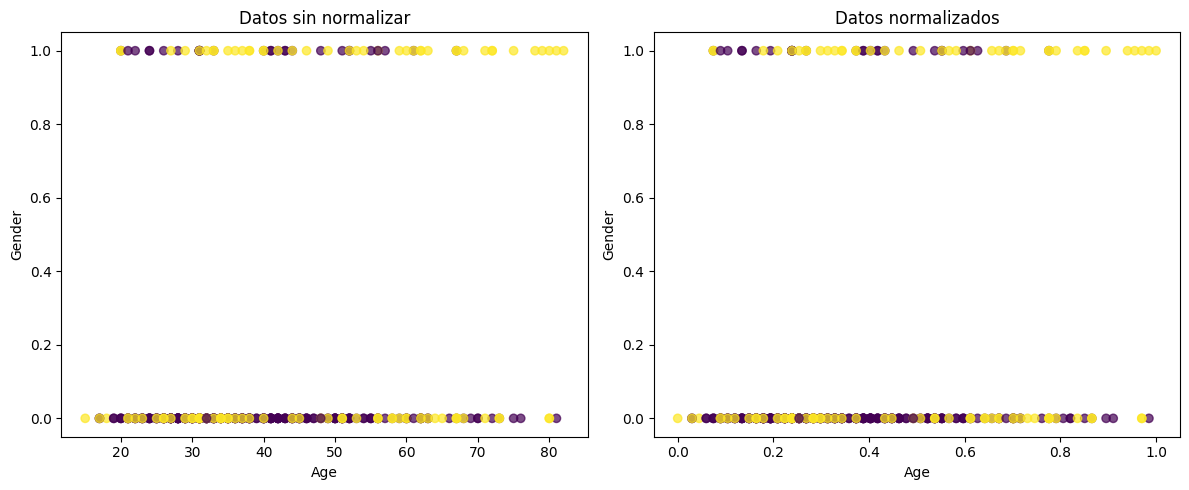

In [ ]:
# Nombres de las features
feature_names = X.columns

# Visualizar los datos usando las dos primeras características antes de normalizar
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.title("Datos sin normalizar")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

# Visualizar los datos después de normalizar
plt.subplot(122)
plt.scatter(X_normalized[:, 0], X_normalized[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.title("Datos normalizados")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

plt.tight_layout()
plt.show()

La normalización no cambia la distribución de los datos, sino su escala: en este caso Age pasó de 15–82 a 0–1, mientras que Gender ya estaba entre 0 y 1.

**¿Por qué es importante normalizar los datos antes de aplicar PCA?**

Es importante normalizar antes de aplicar PCA (Análisis de Componentes Principales) porque las features tienen diferentes escalas. Al llevarlas al mismo rango, todas las características estarán en el mismo rango (entre 0 y 1) y evitamos que aquellas que poseen valores numéricos mayores tengan más peso o dominen a otras en la obtención de los componentes principales.
O sea, queremos que PCA decida qué variable es importante por la información que aporta y no simplemente porque sus números son más grandes.

Aplicamos PCA para poder visualizar los datos en una gráfica 2D:

In [ ]:
from sklearn.decomposition import PCA

# Crear y aplicar PCA
pca = PCA()

# Transformar los datos normalizados en componentes principales
X_pca = pca.fit_transform(X_normalized)

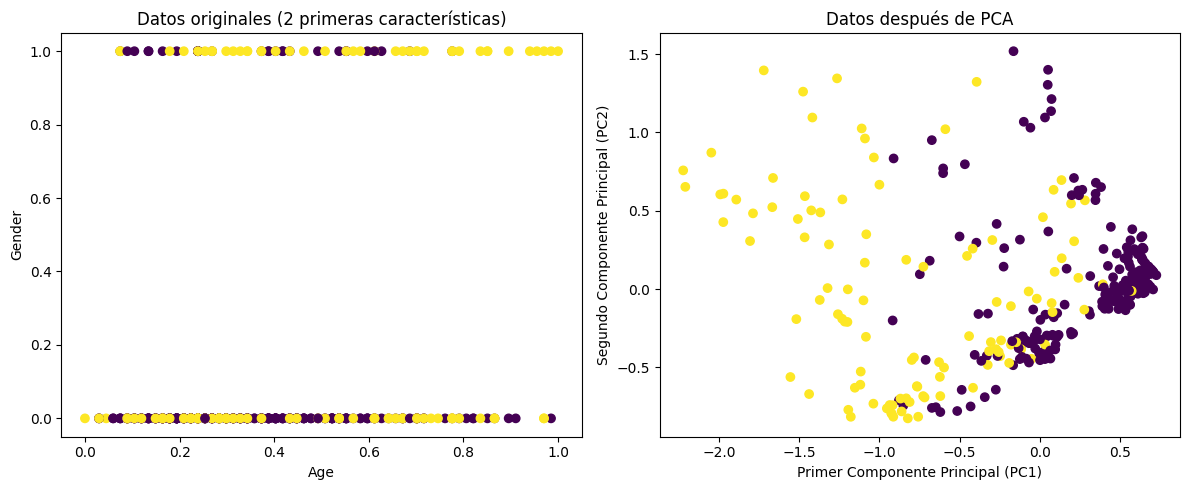

In [ ]:
# Nombres de las características
feature_names = X.columns

# Visualizar los datos originales usando las dos primeras características
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.scatter(
    X_normalized[:, 0],
    X_normalized[:, 1],
    c=y
)

plt.title("Datos originales (2 primeras características)")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

# Visualizar los datos después de aplicar PCA
plt.subplot(122)
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y
)

plt.title("Datos después de PCA")
plt.xlabel("Primer Componente Principal (PC1)")
plt.ylabel("Segundo Componente Principal (PC2)")

plt.tight_layout()
plt.show()

El **amarillo** representa a los pacientes con recurrencia del cáncer y el **morado** a los pacientes sin recurrencia.

Al aplicar PCA, estamos transformando las 16 features en dos nuevas variables: PC1 y PC2.

A la izquierda se graficó las 2 primeras features: Age y Gender. Al estar normalizadas, solo pueden ser 0 o 1, por eso se ven dos "líneas" allí.

A la derecha se graficó PC1 y PC2, muchos pacientes con recurrencia están de un solo lado, mas distribuidos, y muchos pacientes sin recurrencia están juntitos. Aunque hay zonas donde se mezclan ambas clases porque PC1+PC2 no las separan perfectamente.

Verificamos la cantidad de varianza que están explicando los primeros componentes principales (PC1 + PC2):


In [ ]:
# Crear un DataFrame con los resultados del PCA
pca_df = pd.DataFrame(data = {
    'standard_deviation': np.sqrt(pca.explained_variance_),
    'proportion_of_variance': pca.explained_variance_ratio_,
    'cumulative_proportion': np.cumsum(pca.explained_variance_ratio_)
})

# Añadir una columna para los componentes principales
pca_df.index = [f'PC{i}' for i in range(1, len(pca_df) + 1)]
pca_df.index.name = 'component'

print("Resumen de PCA:")
print(pca_df)
print("\n")

Resumen de PCA:
           standard_deviation  proportion_of_variance  cumulative_proportion
component                                                                   
PC1                  0.700970                0.344798               0.344798
PC2                  0.434093                0.132231               0.477028
PC3                  0.398809                0.111608               0.588637
PC4                  0.328818                0.075871               0.664508
PC5                  0.309794                0.067346               0.731854
PC6                  0.262210                0.048246               0.780100
PC7                  0.239072                0.040107               0.820208
PC8                  0.222014                0.034588               0.854796
PC9                  0.206392                0.029892               0.884688
PC10                 0.198165                0.027556               0.912244
PC11                 0.193680                0.026323       

Vemos que los dos primeros componentes principales juntos (PC1+PC2) logran resumir el 47,7 % de la información/variabilidad de los datos originales.

Obtenemos los vectores cargas : muestran cuánto aporta cada feature a cada componente principal

**En base a los vectores cargas, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

In [ ]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(
    loadings,
    columns=[f'PC{i}' for i in range(1, len(loadings[0]) + 1)],
    index=X.columns
)

print("Vectores de carga (Loadings):")
print(loadings_df)
print("\n")

Vectores de carga (Loadings):
                           PC1       PC2       PC3       PC4       PC5  \
Age                  -0.109632  0.121691 -0.107089  0.189744 -0.116903   
Gender               -0.296507  0.591951  0.041229 -0.473492  0.264179   
Smoking              -0.265787  0.514432 -0.050898  0.000216  0.022722   
Hx Smoking           -0.061597  0.204632  0.014798  0.101089 -0.205031   
Hx Radiothreapy      -0.053498  0.089016 -0.000195  0.080162 -0.051021   
Thyroid Function     -0.018659 -0.012303  0.031962  0.010480  0.082068   
Physical Examination  0.151796  0.162736  0.343191  0.509616  0.702488   
Adenopathy            0.099355 -0.029022  0.050815  0.188680  0.162553   
Pathology            -0.002493 -0.240276  0.290734 -0.452992  0.258932   
Focality              0.499572  0.339174  0.638184 -0.049821 -0.443048   
Risk                  0.382249  0.049006 -0.189368 -0.239233  0.199521   
T                    -0.223553  0.001427  0.026071  0.138899 -0.049042   
N       

**En base a los vectores cargas, ¿cuál es la features más relevante para PC1? ¿Y para PC2?**

Para PC1 (en valor absoluto):

*   Focality = 0.4996 → la más relevante
*   N = 0.4565 → segunda
*   Risk = 0.3822 → tercera

Para PC2:

- Gender = 0.5920 → la más relevante
- Smoking = 0.5144 → segunda
- Focality = 0.3392 → tercera

**Hacemos el biplot**

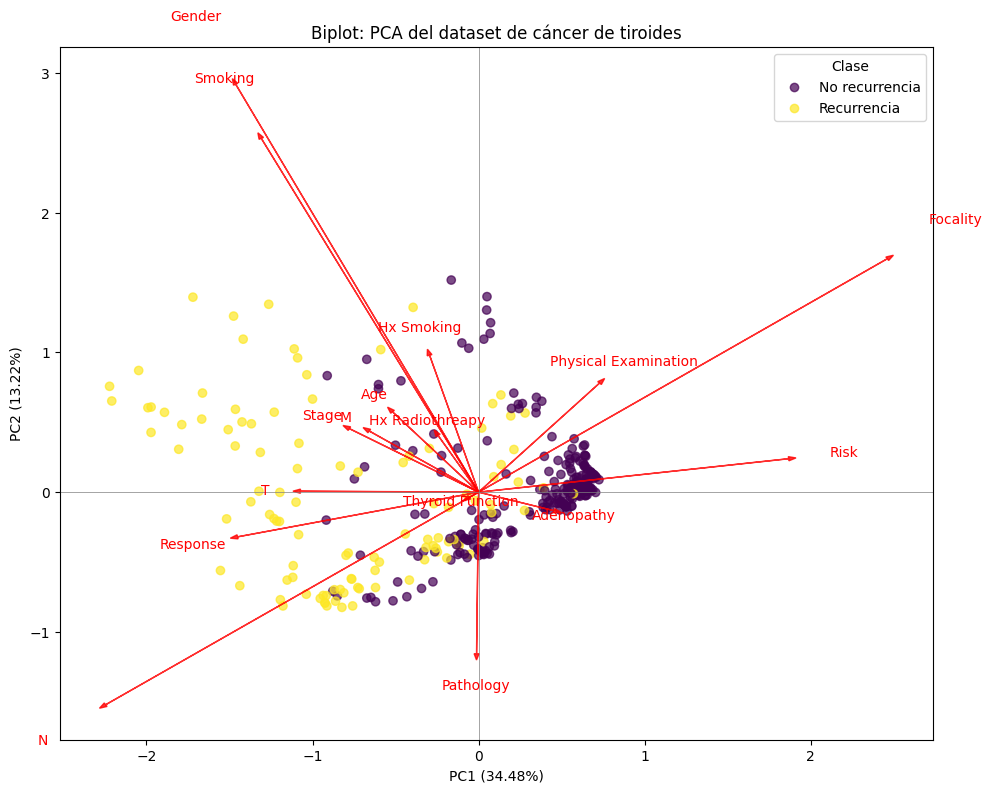

In [ ]:
plt.figure(figsize=(10, 8))

# Graficar los pacientes en PC1 y PC2
sc = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis',
    alpha=0.7
)

# Factor para agrandar las flechas
escala = 5

# Dibujar los vectores de carga
for i, (lx, ly) in enumerate(zip(loadings[:, 0], loadings[:, 1])):

    plt.arrow(
        0, 0,
        lx * escala,
        ly * escala,
        color='r',
        alpha=0.8,
        head_width=0.03,
        length_includes_head=True
    )

    plt.text(
        lx * escala * 1.15,
        ly * escala * 1.15,
        X.columns[i],
        color='r',
        ha='center',
        va='center'
    )

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)

plt.legend(
    sc.legend_elements()[0],
    ['No recurrencia', 'Recurrencia'],
    title='Clase'
)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')

plt.title('Biplot: PCA del dataset de cáncer de tiroides')

plt.tight_layout()
plt.show()

Las flechas representan las features:
- flecha larga → esa variable aporta bastante al plano PC1–PC2;
- más horizontal → influye más en PC1;
- más vertical → influye más en PC2;
- flechas en direcciones parecidas → variables relacionadas entre sí.

**En base al biplot, ¿cuál es la features más relevante para PC1? ¿Y para PC2?**

PC1: La feature más importante es Focality porque su flecha se extiende más sobre el eje horizontal. Le siguen las features N y Risk.

PC2: La feature más importante es Gender porque se extiende más sobre el eje vertical, luego Smoking y Focality.

# **5) Machine Learning**

`Random Forest`

Verificamosque en ‘X’ sigamos teniendo las features y en ‘y’ las etiquetas (clases)

In [ ]:
# Verificar que X contenga las features
print("Features guardadas en X:")
print(X.head())

# Verificar que y contenga las clases
print("\nClases guardadas en y:")
print(y.head())

# Mostrar las dimensiones
print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

# Mostrar las clases posibles
print("\nClases:", y.unique())

Features guardadas en X:
   Age  Gender  Smoking  Hx Smoking  Hx Radiothreapy  Thyroid Function  \
0   27       0        0           0                0                 2   
1   34       0        0           1                0                 2   
2   30       0        0           0                0                 2   
3   62       0        0           0                0                 2   
4   62       0        0           0                0                 2   

   Physical Examination  Adenopathy  Pathology  Focality  Risk  T  N  M  \
0                     3           3          2         1     2  0  0  0   
1                     1           3          2         1     2  0  0  0   
2                     4           3          2         1     2  0  0  0   
3                     4           3          2         1     2  0  0  0   
4                     1           3          2         0     2  0  0  0   

   Stage  Response  
0      0         2  
1      0         1  
2      0        

Entrenamos un modelo Random Forest habilitando oob_score=True.


In [ ]:
# Importar Random Forest
from sklearn.ensemble import RandomForestClassifier

# Definir el modelo Random Forest con evaluación OOB
rf_model = RandomForestClassifier(
    n_estimators=1000,   # Cantidad de árboles del bosque
    oob_score=True,      # Habilitar evaluación Out-Of-Bag
    random_state=0       # Para obtener siempre el mismo resultado
)

# Entrenar el modelo con las features y las clases
rf_model.fit(X, y)

RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)

Obtenemos e interpretamos la precisión OOB

In [ ]:
# Imprimir un resumen del modelo Random Forest
print("Resumen del modelo Random Forest:")

print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {rf_model.classes_}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.9634
Número de características: 16
Clases: [0 1]


El modelo de Random Forest predijo correctamente el 96,34% de los pacientes utilizando las predicciones OOB.

Realizamos una matriz de confusión utilizando las predicciones OOB.

In [ ]:
# Importar la matriz de confusión
from sklearn.metrics import confusion_matrix

# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir las probabilidades OOB a etiquetas de clase
# Se elige la clase con mayor probabilidad
oob_predicted_labels = rf_model.classes_[
    np.argmax(oob_predictions, axis=1)
]

# Crear la matriz de confusión
conf_matrix = confusion_matrix(
    y,
    oob_predicted_labels,
    labels=rf_model.classes_
)

# Convertir la matriz a un DataFrame para verla más claramente
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=['No recurrencia', 'Recurrencia'],
    columns=['No recurrencia', 'Recurrencia']
)

print("Matriz de Confusión OOB:")
print(conf_matrix_df)

Matriz de Confusión OOB:
                No recurrencia  Recurrencia
No recurrencia             272            3
Recurrencia                 11           97


La matriz muestra que clasificó bien a 272 pacientes que no tienen recurrencia de la enfermedad. Mientras que predijo 3 falsos positivos.
Clasificó bien a 97 pacientes que tienen recurrencia de la enfermedad. Mientras que predijo 11 falsos negativos.

Ordenamos las caracteristicas por importancia

In [ ]:
# Obtener la importancia de cada característica
feature_importance = rf_model.feature_importances_

# Obtener los nombres de las características
feature_names = X.columns

# Ordenar los índices de mayor a menor importancia
sorted_idx = np.argsort(feature_importance)[::-1]

# Ordenar los valores de importancia
sorted_feature_importance = feature_importance[sorted_idx]

# Ordenar los nombres de las características
sorted_feature_names = np.array(feature_names)[sorted_idx]

# Mostrar las características ordenadas por importancia
print("Características ordenadas por importancia:")

for feature, importance in zip(
    sorted_feature_names,
    sorted_feature_importance
):
    print(f"{feature}: {importance:.4f}")

Características ordenadas por importancia:
Response: 0.4143
Risk: 0.1631
N: 0.0968
T: 0.0721
Age: 0.0634
Adenopathy: 0.0539
Stage: 0.0382
Physical Examination: 0.0198
Focality: 0.0184
Thyroid Function: 0.0142
Gender: 0.0138
Pathology: 0.0125
Smoking: 0.0101
M: 0.0063
Hx Smoking: 0.0028
Hx Radiothreapy: 0.0005


Gráficamente:

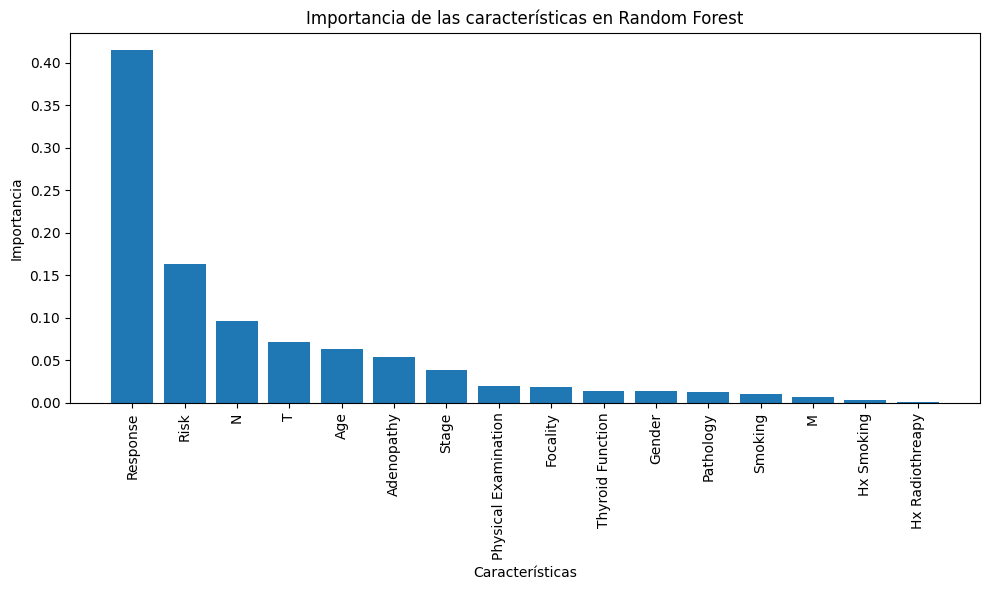

In [ ]:
# Crear gráfico de barras de importancia de las características

plt.figure(figsize=(10, 6))

plt.bar(
    range(len(sorted_feature_importance)),
    sorted_feature_importance
)

# Colocar los nombres de las características
plt.xticks(
    range(len(sorted_feature_names)),
    sorted_feature_names,
    rotation=90
)

# Títulos y etiquetas
plt.xlabel("Características")
plt.ylabel("Importancia")
plt.title("Importancia de las características en Random Forest")

plt.tight_layout()
plt.show()

**¿Qué ventajas tiene la evaluación OOB? ¿En qué se diferencia de evaluar el modelo con un conjunto de test independiente?**


La evaluación OOB permite saber qué tan bien funciona el Random Forest usando los datos que quedaron afuera del entrenamiento de cada árbol. La ventaja es que no hace falta separar un conjunto de test aparte.

En cambio, con un test independiente, se separa desde el principio una parte de los datos y esa parte no se usa para entrenar, sino solo para evaluar el modelo al final.

En ambos casos la idea es la misma: evaluar el modelo con datos que nunca vio o nunca usó para aprender.

`Árbol de decisión`

Dividimos los datos en conjuntos de entrenamiento y prueba

In [ ]:
# Importar train_test_split
from sklearn.model_selection import train_test_split

# Dividir los datos:
# 80% para entrenamiento y 20% para prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,       # 20% para prueba
    random_state=42,     # Para obtener siempre la misma división
    stratify=y           # Mantiene la proporción de las clases
)

# Verificar el tamaño de cada conjunto
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (306, 16)
X_test: (77, 16)
y_train: (306,)
y_test: (77,)


Definimos y entrenamos un modelo de Árbol de decisión

In [ ]:
# Importar el clasificador de Árbol de Decisión
from sklearn.tree import DecisionTreeClassifier

# Definir el modelo
clf = DecisionTreeClassifier(
    criterion="entropy",
    min_impurity_decrease=0.03,
    random_state=0,
    min_samples_leaf=5
)

# Entrenar el modelo con los datos de entrenamiento
clf.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.03,
                       min_samples_leaf=5, random_state=0)

**min_samples_leaf=5**: cada hoja final del árbol debe tener al menos 5 datos/pacientes.

**min_impurity_decrease=0.03**: el árbol solo hace una nueva división si esa división reduce la impureza al menos 0,03, es decir, si mejora suficientemente la separación entre clases.

In [ ]:
# Predecir las etiquetas para los datos de prueba y calcular la precisión del modelo
y_pred = clf.predict(X_test)  # Usamos los datos que el modelo nunca vio

accuracy = accuracy_score(
    y_test,
    y_pred
)  # Comparamos la verdad con la predicción para obtener la precisión

# Imprimir la precisión del modelo
print("Precisión del modelo: {:.2f}".format(accuracy))

Precisión del modelo: 0.96


In [ ]:
# Imprimir información sobre el árbol
print(f'Profundidad del árbol: {clf.get_depth()}')
print(f'Número de hojas: {clf.get_n_leaves()}')

Profundidad del árbol: 3
Número de hojas: 4


In [ ]:
# Imprimir las características más importantes ordenadas

importances = clf.feature_importances_

# Ordenar los índices en orden descendente
sorted_indices = np.argsort(importances)[::-1]

print('Variables más importantes ordenadas:')

for idx in sorted_indices:
    feature_name = X.columns[idx]
    importance = importances[idx]

    print(f'{feature_name}: {importance}')

Variables más importantes ordenadas:
Response: 0.8483776936505035
Risk: 0.09851315786670367
Age: 0.05310914848279295
M: 0.0
N: 0.0
T: 0.0
Focality: 0.0
Stage: 0.0
Pathology: 0.0
Adenopathy: 0.0
Thyroid Function: 0.0
Physical Examination: 0.0
Hx Radiothreapy: 0.0
Hx Smoking: 0.0
Smoking: 0.0
Gender: 0.0


**Las características más importantes, ¿coinciden con lo observado en Random forest?**


Las dos primeras características más importantes son las mismas en el modelo de Random forest y en el modelo de Árbol de decisión: Response y Risk. La tercera característica más importante en el Árbol de decisión es "Age", mientras que en Random Forest es "N", que se refiere a la afectación de ganglios linfáticos.

Realizamos un plot del árbol entrenado y lo guardamos en PDF.

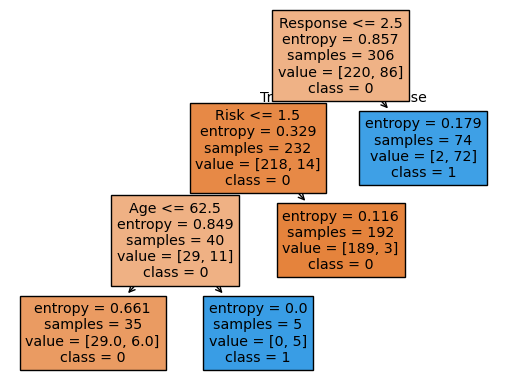

In [ ]:
# Graficar el Árbol de Decisión
plot_tree(
    clf,
    filled=True,
    feature_names=X.columns,
    class_names=[str(cls) for cls in clf.classes_]
)

# Guardar el árbol en formato PDF
plt.savefig('decision_tree.pdf', format='pdf')

# Mostrar el árbol en pantalla
plt.show()

samples= 306 pacientes porque el árbol fue entrenado con el cjto. de entrenamiento (el 80%).

El cjto. de test tiene 77 pacientes.



---



**Optativo: Sumar al análisis SVM y deep learning y hacer una tabla comparativa**

In [ ]:
# Subdividir el conjunto de entrenamiento en train y validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    train_size=0.8,
    test_size=0.2,
    random_state=42,
    stratify=y_train #se agregó por el desbalance de las clases
)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 244
Tamaño del conjunto de validación: 62
Tamaño del conjunto de prueba: 77


**Train (entrenamiento):** datos que el modelo usa para aprender.

**Validation (validación):** datos que usamos para probar distintas configuraciones o hiperparámetros y elegir la mejor.

**Test (prueba):** datos que se guardan hasta el final para evaluar qué tan bien funciona el modelo con datos que nunca vio.

En el código primero separamos 80% train y 20% test, y después dividimos ese 80% de train otra vez para obtener train real + validation.
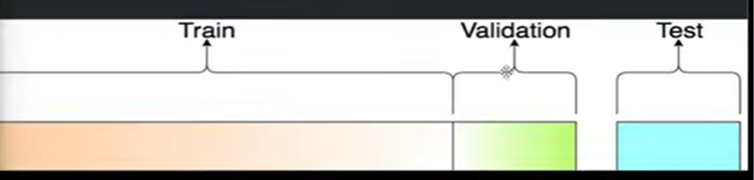

Los kernels sirven para ayudar a SVM a separar las clases cuando no se pueden dividir bien con una línea recta.
- Kernel radial: crea fronteras curvas y flexibles, sirve cuando la separación entre las clases es más compleja.

- Kernel polinomial: busca una separación con forma polinómica, como curvas de distintos grados.

In [ ]:
# Mostrar la frecuencia de las clases en cada conjunto

print("Frecuencia de clases en entrenamiento:")
print(y_train.value_counts())

print("\nFrecuencia de clases en validación:")
print(y_val.value_counts())

print("\nFrecuencia de clases en test:")
print(y_test.value_counts())

Frecuencia de clases en entrenamiento:
Recurred
0    175
1     69
Name: count, dtype: int64

Frecuencia de clases en validación:
Recurred
0    45
1    17
Name: count, dtype: int64

Frecuencia de clases en test:
Recurred
0    55
1    22
Name: count, dtype: int64


El valor C indica cuanto penaliza el modelo los errores:

In [ ]:
# Valores de C a evaluar
valores_C = np.logspace(-5, 5, num=11)

# Tomamos valores de C desde 1x10^-5 hasta 1x10^5
# Es decir, desde valores muy pequeños hasta valores muy grandes

In [ ]:
valores_C

array([1.e-05, 1.e-04, 1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02,
       1.e+03, 1.e+04, 1.e+05])

Con kernel radial:

Mejor valor de C: 1000.0
Precisión máxima: 0.9838709677419355
Error mínimo en validación: 1.61%


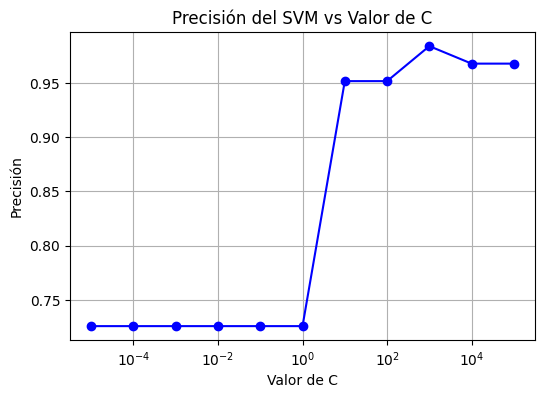


Resultados en el conjunto de prueba:
Mejor valor de C utilizado: 1000.0
Precisión en test: 0.9090909090909091
Error en test: 9.09%

Matriz de Confusión:
[[51  4]
 [ 3 19]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94        55
           1       0.83      0.86      0.84        22

    accuracy                           0.91        77
   macro avg       0.89      0.90      0.89        77
weighted avg       0.91      0.91      0.91        77



In [ ]:
# Importar SVM y métricas
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:

    # Entrenar el modelo SVM con kernel radial y el valor actual de C
    modelo_svm = SVC(kernel='rbf', C=C)
    modelo_svm.fit(X_train, y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='rbf', C=mejor_C)
modelo_svm_final.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_test = accuracy_score(y_test, predicciones_test)

error_test = 1 - precision_test
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Mejor valor de C utilizado: {mejor_C}")
print(f"Precisión en test: {precision_test}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test, predicciones_test)

# Crear reporte de clasificación
reporte_clasificacion = classification_report(
    y_test,
    predicciones_test
)

print("\nMatriz de Confusión:")
print(matriz_confusion)

print("\nReporte de Clasificación:")
print(reporte_clasificacion)

Con Kernel polinomial

Mejor valor de C: 1000.0
Precisión máxima: 0.9516129032258065
Error mínimo en validación: 4.84%


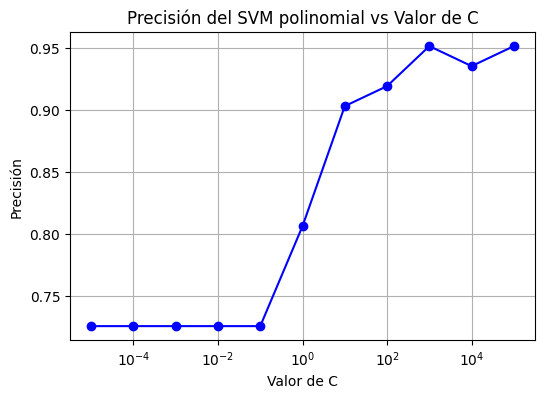


Resultados en el conjunto de prueba:
Mejor valor de C utilizado: 1000.0
Precisión en test: 0.935064935064935
Error en test: 6.49%

Matriz de Confusión:
[[53  2]
 [ 3 19]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95        55
           1       0.90      0.86      0.88        22

    accuracy                           0.94        77
   macro avg       0.93      0.91      0.92        77
weighted avg       0.93      0.94      0.93        77



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones_poly = []

# Bucle sobre los valores de C
for C in valores_C:

    # Entrenar el modelo SVM con kernel polinomial
    modelo_svm = SVC(kernel='poly', C=C)
    modelo_svm.fit(X_train, y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones_poly.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C_poly = valores_C[np.argmax(precisiones_poly)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones_poly)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C_poly}")
print(f"Precisión máxima: {max(precisiones_poly)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones_poly, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM polinomial vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_poly = SVC(kernel='poly', C=mejor_C_poly)
modelo_svm_poly.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test_poly = modelo_svm_poly.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_test_poly = accuracy_score(
    y_test,
    predicciones_test_poly
)

error_test_poly = 1 - precision_test_poly
error_porcentaje_test_poly = round(error_test_poly * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Mejor valor de C utilizado: {mejor_C_poly}")
print(f"Precisión en test: {precision_test_poly}")
print(f"Error en test: {error_porcentaje_test_poly}%")

# Crear matriz de confusión
matriz_confusion_poly = confusion_matrix(
    y_test,
    predicciones_test_poly
)

# Reporte de clasificación
reporte_clasificacion_poly = classification_report(
    y_test,
    predicciones_test_poly
)

print("\nMatriz de Confusión:")
print(matriz_confusion_poly)

print("\nReporte de Clasificación:")
print(reporte_clasificacion_poly)

In [ ]:
# Crear tabla comparativa entre kernel radial y polinomial
comparacion_svm = pd.DataFrame({
    'Kernel': ['Radial (RBF)', 'Polinomial'],
    'Mejor C': [1000, 1000],
    'Precisión en validación': [0.9838709677419355, 0.9516129032258065],
    'Precisión en test': [0.9090909090909091, 0.935064935064935]
})

comparacion_svm

,Kernel,Mejor C,Precisión en validación,Precisión en test
0,Radial (RBF),1000,0.983871,0.909091
1,Polinomial,1000,0.951613,0.935065


In [ ]:
# Comparar matrices de confusión

print("Matriz de confusión - Kernel Radial (RBF):")
print(matriz_confusion)

print("\nMatriz de confusión - Kernel Polinomial:")
print(matriz_confusion_poly)


# Comparar reportes de clasificación

print("\nReporte de clasificación - Kernel Radial (RBF):")
print(reporte_clasificacion)

print("\nReporte de clasificación - Kernel Polinomial:")
print(reporte_clasificacion_poly)


# Comparar precisión final en test

print("\nComparación final:")
print(f"Precisión kernel Radial: {precision_test:.4f}")
print(f"Precisión kernel Polinomial: {precision_test_poly:.4f}")

if precision_test_poly > precision_test:
    print("\nEl kernel Polinomial tuvo mejor rendimiento en el conjunto de test.")
elif precision_test > precision_test_poly:
    print("\nEl kernel Radial tuvo mejor rendimiento en el conjunto de test.")
else:
    print("\nAmbos kernels tuvieron la misma precisión en test.")

Matriz de confusión - Kernel Radial (RBF):
[[51  4]
 [ 3 19]]

Matriz de confusión - Kernel Polinomial:
[[53  2]
 [ 3 19]]

Reporte de clasificación - Kernel Radial (RBF):
              precision    recall  f1-score   support

           0       0.94      0.93      0.94        55
           1       0.83      0.86      0.84        22

    accuracy                           0.91        77
   macro avg       0.89      0.90      0.89        77
weighted avg       0.91      0.91      0.91        77


Reporte de clasificación - Kernel Polinomial:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95        55
           1       0.90      0.86      0.88        22

    accuracy                           0.94        77
   macro avg       0.93      0.91      0.92        77
weighted avg       0.93      0.94      0.93        77


Comparación final:
Precisión kernel Radial: 0.9091
Precisión kernel Polinomial: 0.9351

El kernel Polinomial tuvo mejor rendim

Deep Learning - Redes neuronales

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir la red neuronal
model = models.Sequential()

model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

model.add(layers.Dense(128, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())

# Capa de salida: tenemos 2 clases (0 y 1)
model.add(layers.Dense(2, activation='softmax'))

In [ ]:
# Compilar el modelo
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [ ]:
# Definir hiperparámetros
epocas = 20 # Recorrerá 20 veces todo el cjto. de entrenamiento
batch_size = 32  # Los datos se procesan en grupos de 32

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.4590 - loss: 1.1266 - val_accuracy: 0.7258 - val_loss: 0.8407
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6434 - loss: 0.6650 - val_accuracy: 0.9032 - val_loss: 0.5401
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6721 - loss: 0.6463 - val_accuracy: 0.2742 - val_loss: 1.0036
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7500 - loss: 0.5859 - val_accuracy: 0.2742 - val_loss: 1.5411
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7664 - loss: 0.5131 - val_accuracy: 0.2903 - val_loss: 1.4304
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7951 - loss: 0.4609 - val_accuracy: 0.3871 - val_loss: 0.9634
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7951 - loss: 0.4444 - val_accuracy: 0.6613 - val_loss: 0.5932
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8115 - loss: 0.3969 - val_accuracy: 0.9516 - val_loss: 0.4331


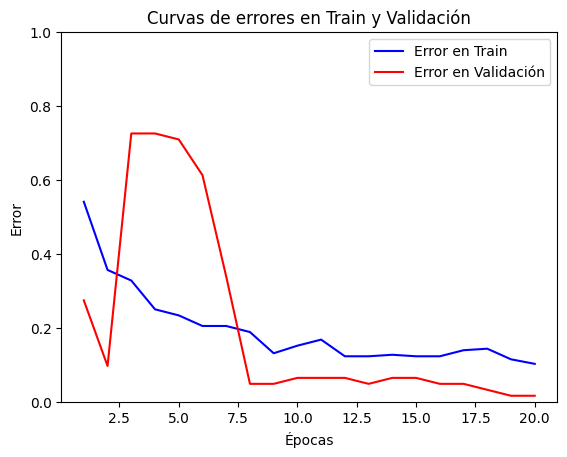

In [ ]:
# Entrenar el modelo y almacenar el historial
history = model.fit(
    X_train,
    y_train,
    epochs=epocas,
    batch_size=batch_size,
    validation_data=(X_val, y_val)
)

# Graficar error en función de las épocas
# Obtener los valores de accuracy y val_accuracy
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Obtener las curvas de error en train y validación
Error_train = [1 - acc for acc in train_accuracy]
Error_val = [1 - acc for acc in val_accuracy]

import matplotlib.pyplot as plt

# Curvas de error en train y validación
epochs = range(1, len(train_accuracy) + 1)

plt.plot(epochs, Error_train, 'b', label='Error en Train')
plt.plot(epochs, Error_val, 'r', label='Error en Validación')

plt.title('Curvas de errores en Train y Validación')
plt.xlabel('Épocas')
plt.ylabel('Error')
plt.ylim([0, 1])
plt.legend()

plt.show()

In [ ]:
# Evaluar el modelo con los datos de test
test_loss, test_accuracy = model.evaluate(X_test, y_test)

# Imprimir el resultado
print(f'\nPérdida en Test: {test_loss}')
print(f'Precisión en Test: {test_accuracy}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9221 - loss: 0.2461

Pérdida en Test: 0.24605418741703033
Precisión en Test: 0.9220778942108154


In [ ]:
# Crear tabla comparativa de los modelos

comparacion_modelos = pd.DataFrame({
    'Modelo': [
        'Random Forest',
        'Árbol de Decisión',
        'SVM Polinomial',
        'Deep Learning'
    ],

    'Precisión': [
        rf_model.oob_score_,
        accuracy,
        precision_test_poly,
        test_accuracy
    ],

    'Tipo de evaluación': [
        'OOB',
        'Test',
        'Test',
        'Test'
    ]
})

comparacion_modelos

,Modelo,Precisión,Tipo de evaluación
0,Random Forest,0.963446,OOB
1,Árbol de Decisión,0.961039,Test
2,SVM Polinomial,0.935065,Test
3,Deep Learning,0.922078,Test
